# 06 — Fields and photometry: `wcc_sim` and `wcc_phot`

The ETC works on one source. `wcc_sim` renders a **full WCC frame** of a real sky position from
Gaia DR3 (plus any extended sources you add), with the same PSF, sensor and noise model as the ETC,
and keeps the truth catalogue with it. `wcc_phot` measures those frames: differential aperture
photometry against an ensemble of comparison stars, and centroiding.

In this notebook:
1. a frame of a Gaia field: `simulate_field`,
2. the truth catalogue and the saturation mask,
3. an injected source and a light curve with `run_photometry`,
4. centroids with `centroid_stars`,
5. writing FITS.

**Memory:** a 2048 px square subarray is three float images of 17 MB each; a full 9576 x 6388 frame
is 20 times that. Use subarrays, and restart the kernel when done.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from wcc_etc import plot_image_mpl
from wcc_sim import simulate_field
from wcc_sim.catalog import query_gaia
from wcc_phot import run_photometry
from wcc_phot.centroid import centroid_stars

***
## 1. A frame of a Gaia field

`query_gaia` fetches (and caches in `gaia_cache/`) the Gaia DR3 sources around a position;
`simulate_field` renders them. Passing the catalogue in with `catalog=` avoids repeating the query
and lets you edit it. The field here is a random spot at (RA, Dec) = (300°, +30°), 60" across.

In [2]:
RA, DEC = 300.0, 30.0
cat = query_gaia(RA, DEC, radius_arcsec=60, mag_limit=21.0, cache_dir="gaia_cache")
field = simulate_field(RA, DEC, sensorfilter="zwo:r", focus=0, exptime=60, seed=1, shape=(2048, 2048), catalog=cat)
PLATE = field.params["plate_scale_mas"]
print(f"{len(cat)} Gaia sources; image {field.image_e.shape}, {PLATE:.2f} mas/px, {field.image_e.shape[0] * PLATE / 1000:.0f}\" on a side")
print("params:", {k: field.params[k] for k in ("exptime", "n_reads", "jitter_sigma_mas", "read_noise", "well_depth", "sky_e_s")})

308 Gaia sources; image (2048, 2048), 16.87 mas/px, 35" on a side
params: {'exptime': 60.0, 'n_reads': 1, 'jitter_sigma_mas': 10.0, 'read_noise': 3.0442890448219115, 'well_depth': 16274.929434794496, 'sky_e_s': 0.013643288040258746}


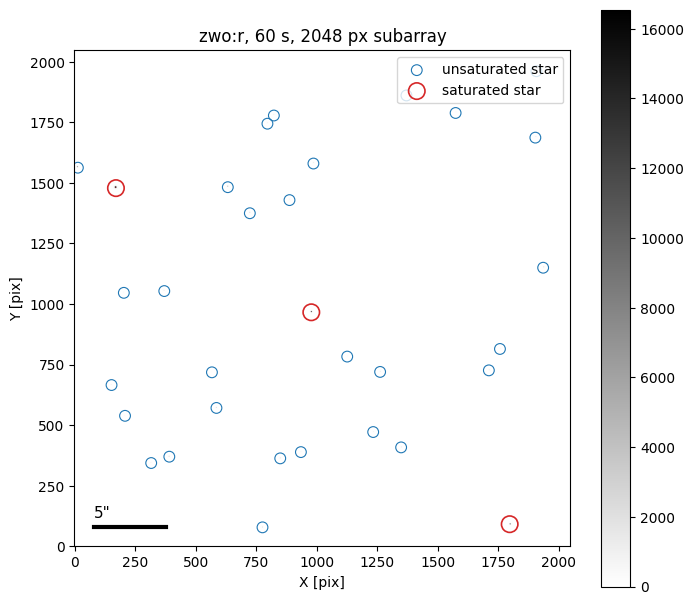

32 stars in the frame, 3 saturated (brightest G = 15.1), 29 saturated pixels


In [3]:
c = field.catalog
inn = np.asarray(c["in_image"], bool); sat = np.asarray(c["saturated"], bool)
fig, ax = plt.subplots(figsize=(8, 7.5))
plot_image_mpl(image_e=field.image_e, saturation_mask=field.saturation_mask, pixel_scale_mas=PLATE,
               show_saturation=True, stretch="asinh", cmap="gray_r", ax=ax)
ax.scatter(c["x"][inn & ~sat], c["y"][inn & ~sat], s=60, facecolors="none", edgecolors="C0", lw=0.8, label="unsaturated star")
ax.scatter(c["x"][inn & sat], c["y"][inn & sat], s=140, facecolors="none", edgecolors="C3", lw=1.2, label="saturated star")
ax.plot([80, 80 + 5000 / PLATE], [80, 80], "k-", lw=3); ax.text(80, 120, '5"', fontsize=11)
ax.legend(loc="upper right"); ax.set_title("zwo:r, 60 s, 2048 px subarray")
plt.show()
print(f"{inn.sum()} stars in the frame, {(inn & sat).sum()} saturated (brightest G = {c['phot_g_mean_mag'][inn].min():.1f}), {int(field.saturation_mask.sum())} saturated pixels")

***
## 2. The truth catalogue

`field.catalog` is the Gaia table plus the rendered pixel positions `x`, `y`, the spectral type
used for the colour (`spt`), the electron rate, and the `in_image` and `saturated` flags. It is the
truth against which `wcc_phot` is checked.

In [4]:
c[inn]["source_id", "phot_g_mean_mag", "phot_bp_mean_mag", "spt", "x", "y", "rate_e_s", "saturated"][:8]

source_id,phot_g_mean_mag,phot_bp_mean_mag,spt,x,y,rate_e_s,saturated
,mag,mag,,,,,
int64,float32,float32,str3,float64,float64,float64,bool
2030222695743477376,15.11599,15.466453,G5V,171.00004882412702,1478.379491280648,34705.47249599846,True
2030222695743480448,17.107054,17.762098,K5V,977.6656921471273,965.6766769782953,5558.985300684932,True
2030222657051207296,17.57171,18.234509,K5V,1796.7825629292233,90.69439508306186,3632.0040543606156,True
2030222695743476352,17.944754,18.49263,K5V,13.809107409615763,1562.6826853040488,2566.062715501909,False
2030222695717090944,18.390272,19.192263,K7V,632.929175709771,1482.2570236749368,1589.9225043617596,False
2030222691407002880,18.721071,20.567642,M5V,1348.5681862381944,407.8354206880741,480.37368102487375,False
2030222760126484224,18.722944,21.077753,M5V,1902.7634762418038,1686.8495419562207,455.7316262571301,False
2030222695743480064,18.914078,19.896759,M0V,723.8817551133034,1374.6700929816443,864.2503181975339,False


***
## 3. An injected source and differential photometry

Add a row to the catalogue (a NaN colour makes `wcc_sim` use its default G2V template), render a
few frames with the injected star at different magnitudes, and recover the light curve with
`run_photometry`: aperture photometry of the target and `n_ref` comparison stars of similar
brightness, normalized by the ensemble.

aperture 9.0 px, 10 reference stars


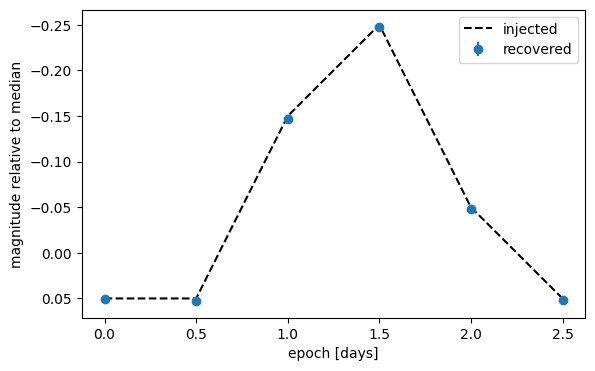

residual RMS 0.9 mmag, propagated error 3.4 mmag; flagged measurements: 0


In [5]:
row = {k: np.nan for k in cat.colnames}
row.update(source_id=1, ra=RA, dec=DEC, phot_g_mean_mag=18.0)
cat.add_row(row)
dmag = np.array([0.0, 0.0, -0.2, -0.3, -0.1, 0.0])                 # the injected light curve, mag
frames = []
for k, dm in enumerate(dmag):
    cat["phot_g_mean_mag"][-1] = 18.0 + dm
    frames.append(simulate_field(RA, DEC, sensorfilter="zwo:r", focus=0, exptime=60, seed=10 + k, shape=(2048, 2048), catalog=cat))
res = run_photometry(frames, target=1, method="aperture", n_ref=10, times=np.arange(len(dmag)) * 0.5)
print(f"aperture {res.params['r_ap']} px, {res.params['n_ref']} reference stars")
lc = res.lightcurve
rec = -2.5 * np.log10(lc["rel_flux_norm"])
rec_err = 2.5 / np.log(10) * lc["rel_flux_norm_err"] / lc["rel_flux_norm"]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(lc["time"], dmag - np.median(dmag), "k--", label="injected")
ax.errorbar(lc["time"], rec, yerr=rec_err, fmt="o", label="recovered")
ax.invert_yaxis(); ax.set(xlabel="epoch [days]", ylabel="magnitude relative to median"); ax.legend()
plt.show()
print(f"residual RMS {1e3 * np.std(rec - (dmag - np.median(dmag))):.1f} mmag, propagated error {1e3 * np.median(rec_err):.1f} mmag; flagged measurements: {int((res.measurements['flags'] != 0).sum())}")

`res.measurements` holds every star in every frame with `flags` (saturation, edge, centroid
failure); `res.stars` lists the target and the comparison stars with their Gaia magnitudes.
`report=path.pdf` writes a diagnostic PDF.

***
## 4. Centroids

`centroid_stars(frame, x0, y0, box)` recentres each star by a background-subtracted centre of mass
in a `box` px window. Against the truth positions this gives the single-frame astrometric precision.

29 stars: per-coordinate scatter 0.68 mas, mean offset (-0.12, +0.14) mas


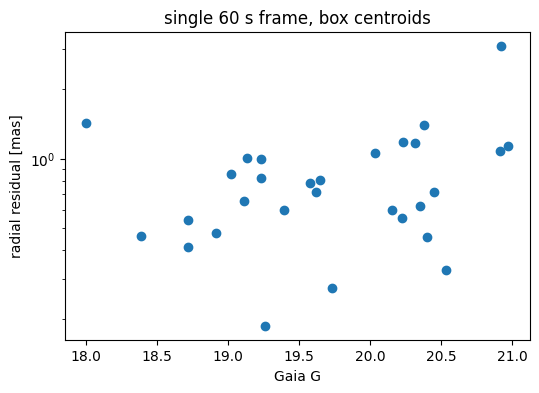

In [6]:
f0 = frames[0]; c = f0.catalog
use = np.asarray(c["in_image"], bool) & ~np.asarray(c["saturated"], bool) & (c["x"] > 20) & (c["x"] < 2027) & (c["y"] > 20) & (c["y"] < 2027)
x, y, flags = centroid_stars(f0, c["x"][use], c["y"][use], box=15)
good = flags == 0
dx = (x - c["x"][use])[good] * PLATE; dy = (y - c["y"][use])[good] * PLATE
print(f"{good.sum()} stars: per-coordinate scatter {0.5 * (dx.std() + dy.std()):.2f} mas, mean offset ({dx.mean():+.2f}, {dy.mean():+.2f}) mas")
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(c["phot_g_mean_mag"][use][good], np.hypot(dx, dy), "o")
ax.set(xlabel="Gaia G", ylabel="radial residual [mas]", title="single 60 s frame, box centroids")
plt.show()

> 🤖 **Ask Jupyter AI:** *Write a loop that renders this field at exposure times 2, 5, 10, 30 and 60 s (same seed), recentroids the unsaturated stars with centroid_stars, and plots the per-coordinate scatter in mas against exposure time with a t^-1/2 reference line.*
>
> That is most of exercise 6.

***
## 5. Writing FITS

`to_hdulist()` packs the frame as SCI, SATMASK, CAT and CLEAN extensions, the format the symposium
S3 bucket uses for simulated WCC data.

In [7]:
hdul = frames[0].to_hdulist()
hdul.info()
# hdul.writeto("wcc_field_300_+30_r_60s.fits", overwrite=True)

Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SCI           1 PrimaryHDU      64   (2048, 2048)   float32   
  1  SATMASK       1 ImageHDU         8   (2048, 2048)   uint8   
  2  CAT           1 BinTableHDU     54   309R x 18C   ['K', 'D', 'D', 'E', 'E', 'E', 'D', 'D', 'D', 'E', 'D', 'D', '3A', 'L', 'D', 'D', 'L', 'L']   
  3  CLEAN         1 ImageHDU         9   (2048, 2048)   float32   


***
## Summary

```python
cat   = query_gaia(ra, dec, radius_arcsec=60, mag_limit=21, cache_dir="gaia_cache")
field = simulate_field(ra, dec, sensorfilter="zwo:r", focus=0, exptime=60, seed=1, shape=(2048, 2048), catalog=cat)
field.image_e, field.saturation_mask, field.catalog, field.params, field.to_hdulist()
res   = run_photometry(frames, target=source_id, n_ref=10, times=...)     # .lightcurve .measurements .stars
x, y, flags = centroid_stars(field, x0, y0, box=15)
```

Now pick an exercise: [README](README.md).